<a href="https://colab.research.google.com/github/ShouryaBatra/fbla-data-analysis/blob/main/olympics_country_specialization_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

In [4]:
athletes = pd.read_csv("athlete_events.csv")
nocs = pd.read_csv("noc_regions.csv")

In [5]:
df = athletes.merge(nocs, on="NOC", how="left")

# Rename region -> Country for clarity
df = df.rename(columns={"region": "Country"})

# Keep Summer Olympics only
df = df[df["Season"] == "Summer"].copy()

# Medal indicators
df["Medal_Won"] = df["Medal"].notna().astype(int)
df["Gold"] = (df["Medal"] == "Gold").astype(int)
df["Silver"] = (df["Medal"] == "Silver").astype(int)
df["Bronze"] = (df["Medal"] == "Bronze").astype(int)

df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,...,City,Sport,Event,Medal,Country,notes,Medal_Won,Gold,Silver,Bronze
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,...,Barcelona,Basketball,Basketball Men's Basketball,NaN,China,NaN,0,0,0,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,...,London,Judo,Judo Men's Extra-Lightweight,NaN,China,NaN,0,0,0,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,...,Antwerpen,Football,Football Men's Football,NaN,Denmark,NaN,0,0,0,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,...,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,Denmark,NaN,1,1,0,0
26,8,"Cornelia ""Cor"" Aalten (-Strannood)",F,18.0,168.0,NaN,Netherlands,NED,1932 Summer,1932,...,Los Angeles,Athletics,Athletics Women's 100 metres,NaN,Netherlands,NaN,0,0,0,0


In [6]:
medals_by_country_sport = (
    df[df["Medal_Won"] == 1]
    .groupby(["Country", "Sport"])["Medal_Won"]
    .sum()
    .reset_index()
)

medals_by_country_sport.head()

,Country,Sport,Medal_Won
0,Afghanistan,Taekwondo,2
1,Algeria,Athletics,9
2,Algeria,Boxing,6
3,Algeria,Judo,2
4,Argentina,Athletics,5


In [7]:
total_medals_by_country = (
    medals_by_country_sport
    .groupby("Country")["Medal_Won"]
    .sum()
    .reset_index(name="Total_Medals")
)

total_medals_by_country.sort_values("Total_Medals", ascending=False).head(10)

,Country,Total_Medals
123,USA,5002
98,Russia,3188
41,Germany,3126
122,UK,1985
38,France,1627
57,Italy,1446
4,Australia,1333
48,Hungary,1123
110,Sweden,1108
82,Netherlands,918


In [8]:
country_sport_share = medals_by_country_sport.merge(
    total_medals_by_country,
    on="Country",
    how="left"
)

country_sport_share["Share"] = (
    country_sport_share["Medal_Won"] / country_sport_share["Total_Medals"]
)

country_sport_matrix = country_sport_share.pivot_table(
    index="Country",
    columns="Sport",
    values="Share",
    fill_value=0
)

country_sport_matrix.shape

(134, 52)

In [9]:
MIN_TOTAL_MEDALS = 20  # tweak later if you want (10, 20, or 50)

valid_countries = total_medals_by_country.query(
    "Total_Medals >= @MIN_TOTAL_MEDALS"
)["Country"]

X = country_sport_matrix.loc[valid_countries].copy()

X.shape

(70, 52)

In [10]:
k = 2
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

clustered = X.copy()
clustered["Cluster"] = clusters

clustered["Cluster"].value_counts()

,count
Cluster,
1,64
0,6


In [11]:
# Effective number of sports = 1 / sum(shares^2)
# Specialists -> lower value, Generalists -> higher value
shares_only = clustered.drop(columns=["Cluster"])
effective_sports = 1 / (shares_only.pow(2).sum(axis=1))

clustered["Effective_Sports"] = effective_sports

cluster_summary = clustered.groupby("Cluster")["Effective_Sports"].mean().sort_values()
cluster_summary

,Effective_Sports
Cluster,
0,1.170317
1,6.785746


In [12]:
# Map clusters to labels based on effective sports
specialist_cluster = cluster_summary.index[0]
generalist_cluster = cluster_summary.index[-1]

label_map = {
    specialist_cluster: "Specialist",
    generalist_cluster: "Generalist"
}

clustered["Cluster_Label"] = clustered["Cluster"].map(label_map)

clustered[["Cluster", "Cluster_Label", "Effective_Sports"]].head()

Sport,Cluster,Cluster_Label,Effective_Sports
Country,,,
Argentina,1,Generalist,5.703996
Australia,1,Generalist,6.906628
Austria,1,Generalist,12.948029
Azerbaijan,1,Generalist,3.063291
Bahamas,0,Specialist,1.219512


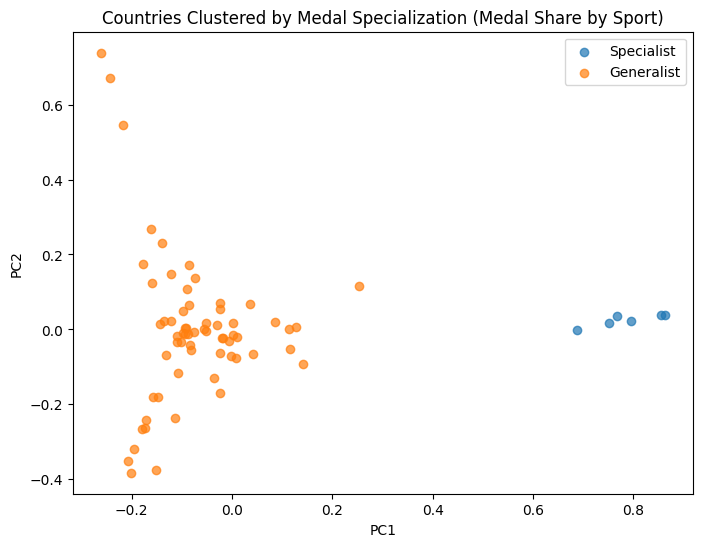

In [15]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

viz = pd.DataFrame(coords, columns=["PC1", "PC2"])
viz["Country"] = X.index
viz["Cluster"] = clusters
viz["Cluster_Label"] = viz["Cluster"].map(label_map)

plt.figure(figsize=(8, 6))
for label in ["Specialist", "Generalist"]:
    subset = viz[viz["Cluster_Label"] == label]
    plt.scatter(subset["PC1"], subset["PC2"], label=label, alpha=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Countries Clustered by Medal Specialization (Medal Share by Sport)")
plt.legend()
plt.show()

In [16]:
specialists = clustered[clustered["Cluster_Label"] == "Specialist"].sort_values("Effective_Sports")
generalists = clustered[clustered["Cluster_Label"] == "Generalist"].sort_values("Effective_Sports", ascending=False)

print("Specialist examples:")
print(specialists.head(10).index.tolist())

print("\nGeneralist examples:")
print(generalists.head(10).index.tolist())

Specialist examples:
['Ethiopia', 'Jamaica', 'Kenya', 'Bahamas', 'Trinidad', 'Morocco']

Generalist examples:
['China', 'Russia', 'Ukraine', 'Sweden', 'France', 'Austria', 'Germany', 'Belgium', 'UK', 'Poland']
